In [11]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, hour, dayofweek, count, avg, when
import matplotlib.pyplot as plt
import pandas as pd

# Delta Lake destegi ile baslat
spark = SparkSession.builder \
    .appName("NYC-Taxi-EDA") \
    .config("spark.jars.packages",
            "io.delta:delta-spark_2.12:3.1.0,"
            "org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.0") \
    .config("spark.sql.extensions",
            "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog",
            "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print("Spark baslatildi.")


Spark baslatildi.


In [12]:
# Egitim verisi: Delta Lake Silver katmanindan oku (Ocak 1-21)
SILVER_PATH = "/home/jovyan/work/data/delta/taxi_trips/silver"

df = spark.read.format("delta").load(SILVER_PATH)
print(f"Toplam satir: {df.count()}")
print(f"Toplam kolon: {len(df.columns)}")
df.printSchema()


Toplam satir: 1800870
Toplam kolon: 19
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)



In [13]:
# Temel istatistikler
print("=== TEMEL İSTATİSTİKLER ===")
df.select(
    "trip_distance", 
    "fare_amount", 
    "tip_amount", 
    "total_amount", 
    "passenger_count"
).describe().show()

=== TEMEL İSTATİSTİKLER ===
+-------+------------------+------------------+------------------+------------------+------------------+
|summary|     trip_distance|       fare_amount|        tip_amount|      total_amount|   passenger_count|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|           1800870|           1800870|           1800870|           1800870|           1800870|
|   mean|3.3899687040152777|18.613035282946417|3.4662546713528775|27.573529122034866| 1.376647953489147|
| stddev| 14.85398752758593|17.653695691159307|3.9182126629157654|22.278927852162983|0.8640849753750477|
|    min|              0.01|               0.0|               0.0|               1.0|                 1|
|    max|          15400.32|             474.8|             422.7|            490.74|                 9|
+-------+------------------+------------------+------------------+------------------+------------------+



In [14]:
# Eksik değer analizi
from pyspark.sql.functions import isnan, isnull, sum as spark_sum

print("=== EKSİK DEĞER ANALİZİ ===")
df.select([
    spark_sum(isnull(c).cast("int")).alias(c) 
    for c in df.columns
]).show()

=== EKSİK DEĞER ANALİZİ ===
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|       0|                   0|                    0|              0|            0|         0|                 0|           0|           0|           0|       

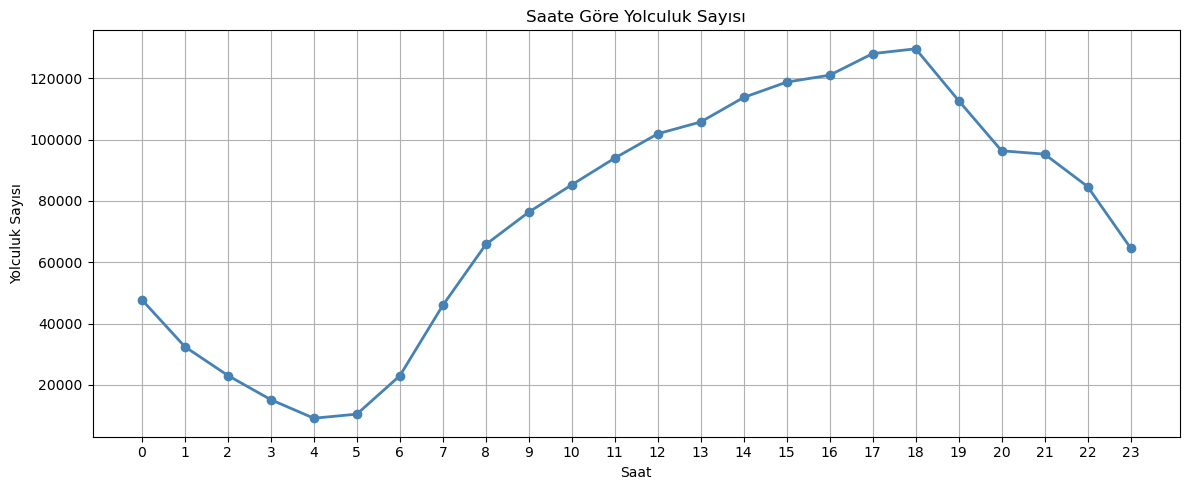

✅ Grafik kaydedildi.


In [15]:
# Saatlik yolculuk trendi
from pyspark.sql.functions import hour

hourly = df.groupBy(hour("tpep_pickup_datetime").alias("hour")) \
    .count() \
    .orderBy("hour") \
    .toPandas()

plt.figure(figsize=(12, 5))
plt.plot(hourly["hour"], hourly["count"], marker="o", color="steelblue", linewidth=2)
plt.title("Saate Göre Yolculuk Sayısı")
plt.xlabel("Saat")
plt.ylabel("Yolculuk Sayısı")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/hourly_trips.png")
plt.show()
print("✅ Grafik kaydedildi.")

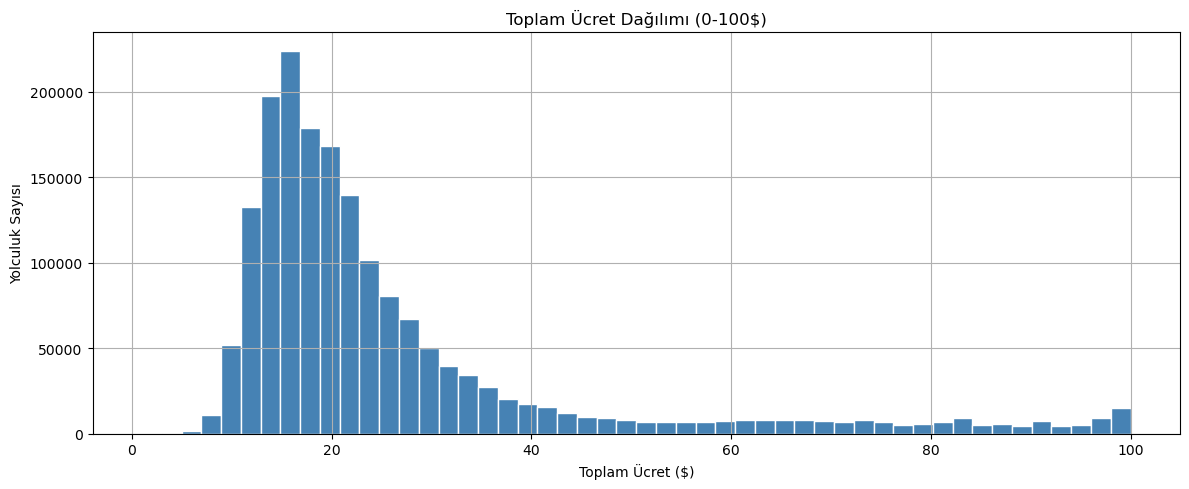

✅ Grafik kaydedildi.


In [16]:
# Total amount dağılımı
amount_df = df.filter(
    (col("total_amount") > 0) & (col("total_amount") < 100)
).select("total_amount").toPandas()

plt.figure(figsize=(12, 5))
plt.hist(amount_df["total_amount"], bins=50, color="steelblue", edgecolor="white")
plt.title("Toplam Ücret Dağılımı (0-100$)")
plt.xlabel("Toplam Ücret ($)")
plt.ylabel("Yolculuk Sayısı")
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/total_amount_dist.png")
plt.show()
print("✅ Grafik kaydedildi.")

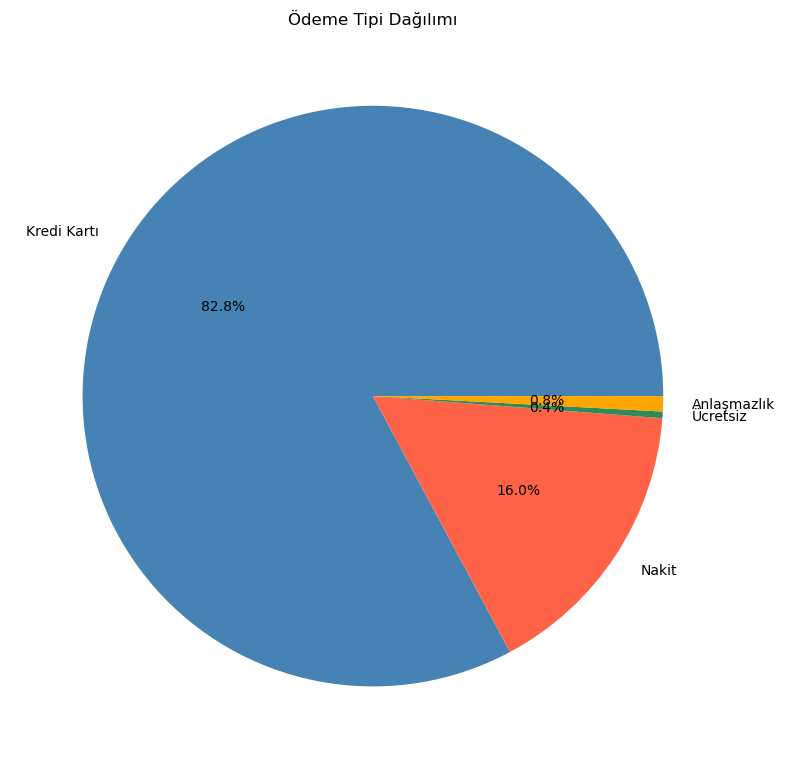

✅ Grafik kaydedildi.


In [17]:
# Ödeme tipi dağılımı
payment_df = df.groupBy("payment_type") \
    .count() \
    .orderBy("payment_type") \
    .toPandas()

payment_labels = {1: "Kredi Kartı", 2: "Nakit", 3: "Ücretsiz", 4: "Anlaşmazlık", 0: "Bilinmiyor"}
payment_df["label"] = payment_df["payment_type"].map(payment_labels)

plt.figure(figsize=(8, 8))
plt.pie(
    payment_df["count"],
    labels=payment_df["label"],
    autopct="%1.1f%%",
    colors=["steelblue", "tomato", "seagreen", "orange", "gray"]
)
plt.title("Ödeme Tipi Dağılımı")
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/payment_type_dist.png")
plt.show()
print("✅ Grafik kaydedildi.")

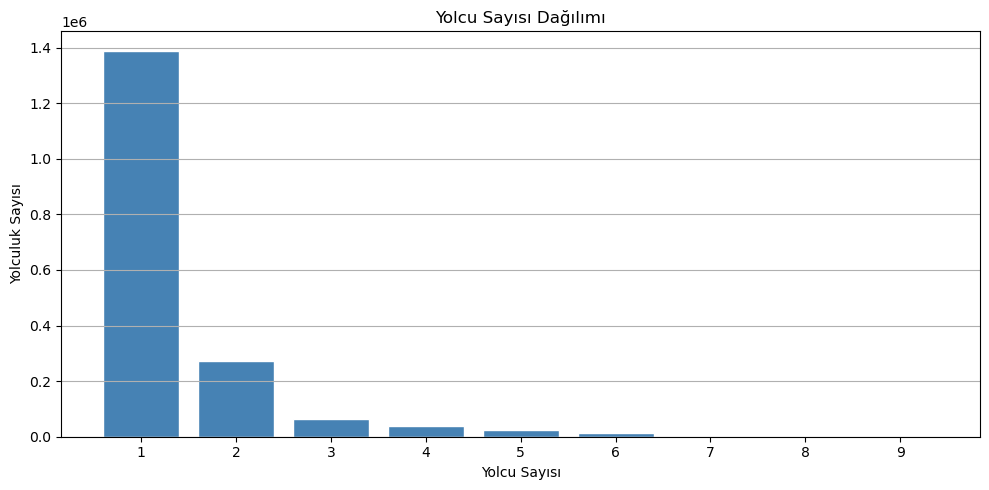

✅ Grafik kaydedildi.


In [18]:
# Yolcu sayısı dağılımı
passenger_df = df.filter(col("passenger_count") > 0) \
    .groupBy("passenger_count") \
    .count() \
    .orderBy("passenger_count") \
    .toPandas()

plt.figure(figsize=(10, 5))
plt.bar(passenger_df["passenger_count"], passenger_df["count"], color="steelblue", edgecolor="white")
plt.title("Yolcu Sayısı Dağılımı")
plt.xlabel("Yolcu Sayısı")
plt.ylabel("Yolculuk Sayısı")
plt.xticks(range(1, 10))
plt.grid(True, axis="y")
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/passenger_count_dist.png")
plt.show()
print("✅ Grafik kaydedildi.")

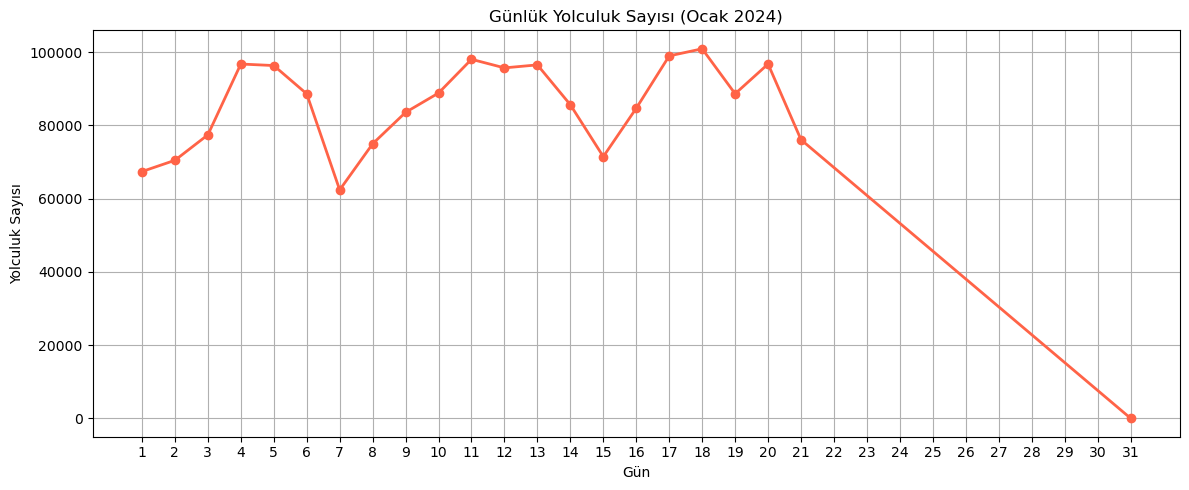

✅ Grafik kaydedildi.


In [19]:
# Günlük yolculuk trendi
from pyspark.sql.functions import dayofmonth

daily_df = df.groupBy(dayofmonth("tpep_pickup_datetime").alias("gun")) \
    .count() \
    .orderBy("gun") \
    .toPandas()

plt.figure(figsize=(12, 5))
plt.plot(daily_df["gun"], daily_df["count"], marker="o", color="tomato", linewidth=2)
plt.title("Günlük Yolculuk Sayısı (Ocak 2024)")
plt.xlabel("Gün")
plt.ylabel("Yolculuk Sayısı")
plt.xticks(range(1, 32))
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/daily_trips.png")
plt.show()
print("✅ Grafik kaydedildi.")

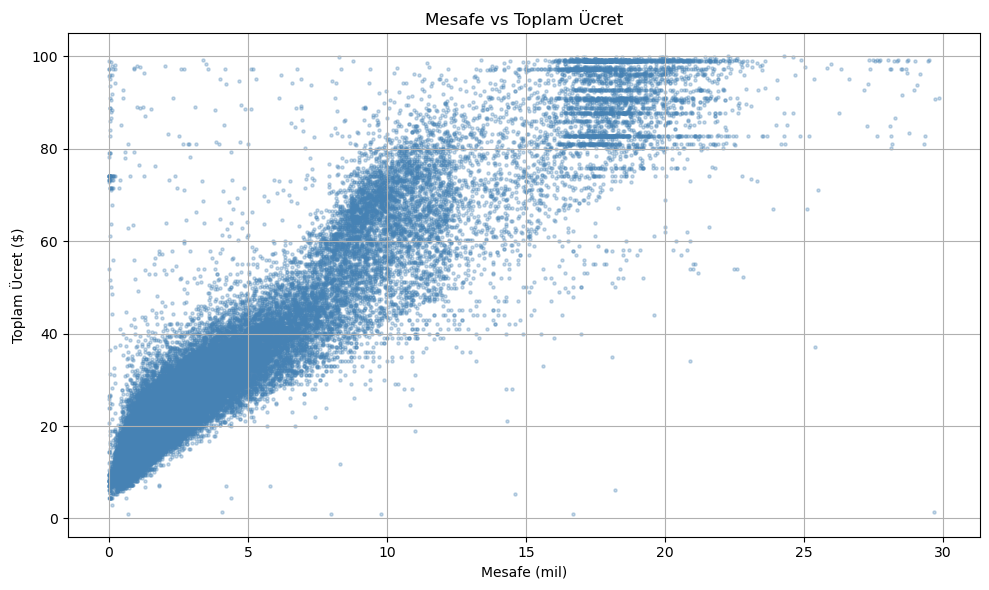

✅ Grafik kaydedildi.


In [20]:
# Mesafe vs Ücret scatter plot
sample_df = df.filter(
    (col("trip_distance") > 0) & (col("trip_distance") < 30) &
    (col("total_amount") > 0) & (col("total_amount") < 100)
).select("trip_distance", "total_amount") \
 .sample(fraction=0.05) \
 .toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(sample_df["trip_distance"], sample_df["total_amount"], 
            alpha=0.3, color="steelblue", s=5)
plt.title("Mesafe vs Toplam Ücret")
plt.xlabel("Mesafe (mil)")
plt.ylabel("Toplam Ücret ($)")
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/distance_vs_amount.png")
plt.show()
print("✅ Grafik kaydedildi.")